# Accessibility Scores
### This notebook contains a focused example of using accessX to estimate accessibility scores for Milan.

The workflow prepares the inputs needed for accessibility analysis and calculates four complementary measures:

- reachable POI counts within a travel-time threshold
- travel cost to the nearest POI by category
- Hansen distance-decay accessibility
- two-step floating catchment area (2SFCA) accessibility

This notebook does not include equity analysis or isochrones.

In [1]:
from pathlib import Path

import accessx as acx
import matplotlib.pyplot as plt
import osmnx as ox
import pandas as pd

## Setup

In [2]:
epsg_mil = 32632

resolution = 9
worldpop_year = 2020
network_buffer_m = 1000
walking_speed_kmh = 4.5
cost_attr = "avg_time"
max_cost = 15
max_distance_from_graph = 200.0

data_path = Path("../data/case_studies/accessibility")
area_path = data_path / "area"
population_path = data_path / "population"
pois_path = data_path / "pois"
street_network_path = data_path / "street_network"
results_path = data_path / "results"

for folder in [data_path, area_path, population_path, pois_path, street_network_path, results_path]:
    folder.mkdir(parents=True, exist_ok=True)

#Add to the list the cities you want to analyze. Make sure to provide the correct EPSG code for each city (Projected CRS).
city_data = [
    {"name": "milan", "label": "Milan", "epsg": epsg_mil},
]

## Load Areas of Interest

Add the AOIs for the cities you want to analyze. You can either geocode them or read them from saved files.

In [ ]:
aois = {
    "milan": ox.geocode_to_gdf("Milan, Italy"),
}

for city in city_data:
    acx.save_gdf(aois[city["name"]], area_path / f"aoi_{city['name']}.geojson")

# Uncomment to read saved AOIs instead of geocoding.
# aois = {
#     city["name"]: acx.read_gdf(area_path / f"aoi_{city['name']}.geojson")
#     for city in city_data
# }

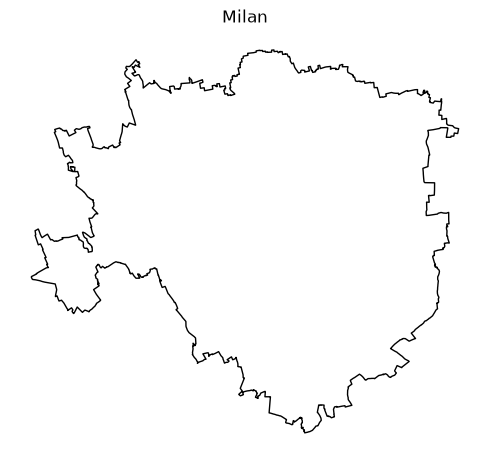

In [4]:
n = len(city_data)
fig, axes = plt.subplots(1, n, figsize=(5 * n, 5), squeeze=False)

for ax, city in zip(axes.flat, city_data):
    aois[city["name"]].plot(ax=ax, facecolor="none", edgecolor="black")
    ax.set_title(city["label"])
    ax.axis("off")

plt.tight_layout()
plt.show()

## Make Hex Grids

Hexagons are the origins for the accessibility calculations.

In [5]:
hexes = {}

for city in city_data:
    name = city["name"]
    hexes[name] = acx.make_hex_grid(aoi=aois[name], resolution=resolution)
    acx.save_gdf(hexes[name], area_path / f"hexes_{name}.geojson")

# Uncomment to read saved hex grids instead of recomputing.
# hexes = {
#     city["name"]: acx.read_gdf(area_path / f"hexes_{city['name']}.geojson")
#     for city in city_data
# }

## Prepare Walking Networks and Travel-Time Costs

The network is downloaded with a buffer so origins near the municipal boundary can still reach destinations just outside it. A constant walking speed is converted into the edge cost column used by all routing-based accessibility functions.

In [6]:
graphs = {}

for city in city_data:
    name = city["name"]
    epsg = city["epsg"]

    graph = acx.build_network(
        AOI=aois[name],
        city_epsg=epsg,
        buffer_m=network_buffer_m,
        network_type="walk",
        simplify=False,
        retain_all=True,
    )
    graph = acx.add_time_cost_constant_speed(
        graph,
        speed_kmh=walking_speed_kmh,
        cost_col=cost_attr,
    )
    graphs[name] = graph

    acx.save_graph(
        graph,
        out_dir=street_network_path,
        base_name=f"{name}_graph_with_cost",
    )

# Uncomment to read saved networks instead of downloading them again.
# graphs = {
#     city["name"]: acx.load_graph(
#         out_dir=street_network_path,
#         base_name=f"{city['name']}_graph_with_cost",
#         crs=city["epsg"],
#     )
#     for city in city_data
# }

## Collect POIs

`poi_groups` defines analytical categories for accessibility while preserving the original OSM key and value in the POI output. Add the POI categories you want to analyse below, using the format: "category": {"osm_key": ["osm_value"]}.

In [ ]:
poi_groups = {
    "healthcare": {
        "amenity": ["pharmacy", "clinic", "doctors", "dentist", "hospital"],
        "healthcare": True,
    },
    "education": {
        "amenity": ["kindergarten", "childcare", "school", "college", "university", "library"],
    },
    "daily_needs": {
        "shop": ["supermarket", "convenience", "greengrocer", "bakery", "butcher", "chemist"],
        "amenity": ["marketplace", "post_office", "bank", "atm"],
    },
}

#Other examples of POI groups that can be used for accessibility analysis:
# poi_groups = {
#     "open_space_and_play": {
#         "leisure": ["park", "playground", "garden", "dog_park", "recreation_ground"],
#     },
#     "public_transport": {
#         "highway": ["bus_stop"],
#         "railway": ["station", "halt", "tram_stop", "subway_entrance"],
#         "public_transport": ["platform", "stop_position", "station"],
#     },
# }

pois = {}
poi_reports = {}

for city in city_data:
    name = city["name"]
    pois[name], poi_reports[name] = acx.get_pois_osm(
        aois[name],
        poi_groups=poi_groups,
        max_retries=4,
        show_progress=True,
        return_report=True,
        columns="minimal",
    )
    # A feature can match more than one OSM query inside the same custom group.
    # Keep one opportunity per category and OSM identity before calculating scores.
    pois[name] = pois[name].drop_duplicates(
        subset=["category", "osm_type", "osmid"]
    ).reset_index(drop=True)
    pois[name]["id"] = range(len(pois[name]))

    acx.save_gdf(pois[name], pois_path / f"pois_{name}.geojson")

# Uncomment to read saved POIs instead of querying OSM again.
# pois = {
#     city["name"]: acx.read_gdf(pois_path / f"pois_{city['name']}.geojson")
#     for city in city_data
# }

In [11]:
poi_summary = []
for city in city_data:
    name = city["name"]
    counts = pois[name].groupby("category").size().rename("pois").reset_index()
    counts.insert(0, "city", city["label"])
    poi_summary.append(counts)

pd.concat(poi_summary, ignore_index=True)

,city,category,pois
0,Milan,daily_needs,2139
1,Milan,education,760
2,Milan,healthcare,859


## 1. Cumulative Opportunity Measure

The cumulative opportunity measure counts how many destinations in each POI category can be reached from each hex within `max_cost` minutes.

In [ ]:
accessible_counts = {}

for city in city_data:
    name = city["name"]
    epsg = city["epsg"]

    accessible_counts[name] = acx.count_accessible_pois(
        graphs[name],
        hexes[name].to_crs(epsg),
        pois[name].to_crs(epsg),
        max_cost=max_cost,
        cost_attr=cost_attr,
        id_col="hex_id",
        category_col="category",
        max_distance_from_graph=max_distance_from_graph,
        show_progress=True,
    )
    acx.save_gdf(accessible_counts[name], results_path / f"accessible_counts_{name}.geojson")

# Uncomment to read saved accessible counts instead of recomputing
# accessible_counts = {
#     city["name"]: acx.read_gdf(results_path / f"accessible_counts_{city['name']}.geojson")
#     for city in city_data
# }

### Visual - Cumulative Opportunity Measure

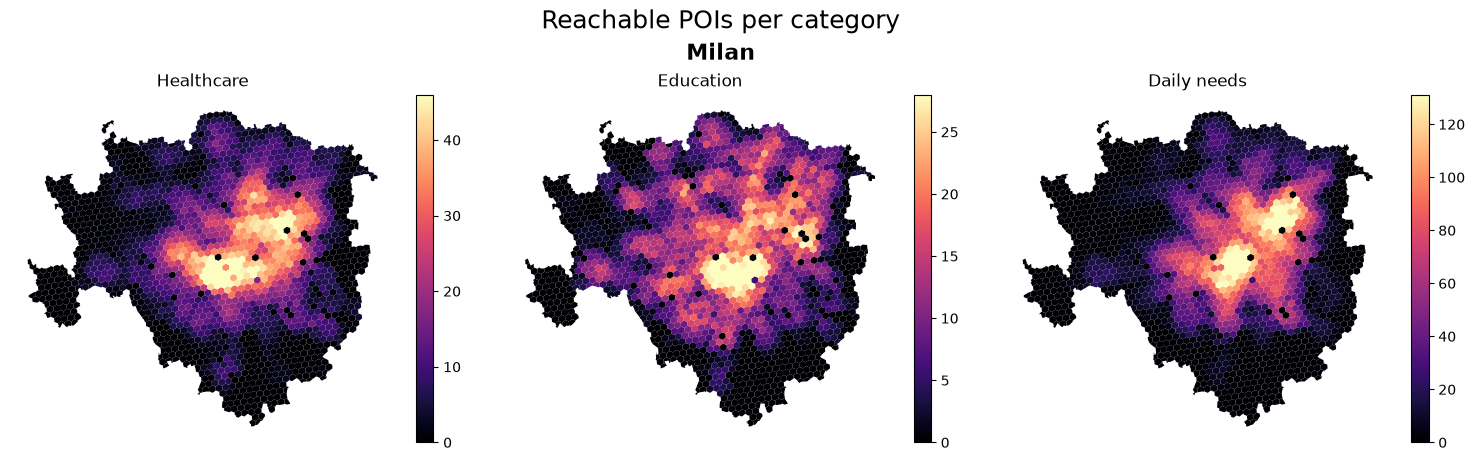

In [ ]:
#Categories and cities to plot 
categories = ["healthcare", "education", "daily_needs"] 
cities = ["milan"]

n_rows, n_cols = len(cities), len(categories)

# Shared colour scale per category (same across cities, so rows are comparable)
limits = {}
for category in categories:
    metric = f"count_{category}"
    limits[category] = (
        min(accessible_counts[city][metric].quantile(0.02) for city in cities),
        max(accessible_counts[city][metric].quantile(0.98) for city in cities),
    )

fig = plt.figure(figsize=(5 * n_cols, 4.5 * n_rows), layout="constrained")
subfigs = fig.subfigures(n_rows, 1, squeeze=False).flat  # one sub-figure per city

for subfig, city in zip(subfigs, cities):
    subfig.suptitle(city.title(), fontsize=16, fontweight="bold")
    axes = subfig.subplots(1, n_cols, squeeze=False).flat

    for ax, category in zip(axes, categories):
        vmin, vmax = limits[category]
        accessible_counts[city].plot(
            column=f"count_{category}",
            ax=ax,
            legend=True,
            cmap="magma",
            vmin=vmin,
            vmax=vmax,
            edgecolor="none",
            missing_kwds={"color": "lightgrey"},
        )
        ax.set_title(category.replace("_", " ").capitalize())
        ax.axis("off")

fig.suptitle("Reachable POIs per category", fontsize=18)
plt.show()


## 2. Nearest POI Cost

Nearest POI cost measures the shortest network travel cost to the nearest reachable destination in each category. The wide output is convenient for mapping and tabular analysis.

In [ ]:
nearest_poi_costs = {}

for city in city_data:
    name = city["name"]
    epsg = city["epsg"]

    nearest_poi_costs[name] = acx.compute_nearest_poi_cost(
        graphs[name],
        hexes[name].to_crs(epsg),
        pois[name].to_crs(epsg),
        max_cost=max_cost,
        cost_attr=cost_attr,
        id_col="hex_id",
        category_col="category",
        poi_id_col="id",
        max_distance_from_graph=max_distance_from_graph,
        number_of_nearest=1,
        output="wide",
        show_progress=True,
    )
    acx.save_gdf(nearest_poi_costs[name], results_path / f"nearest_poi_costs_{name}.geojson")

# Uncomment to read saved nearest costs counts instead of recomputing
# nearest_poi_costs = {
#     city["name"]: acx.read_gdf(results_path / f"nearest_poi_costs_{city['name']}.geojson")
#     for city in city_data
# }


### Visual Nearest POIs

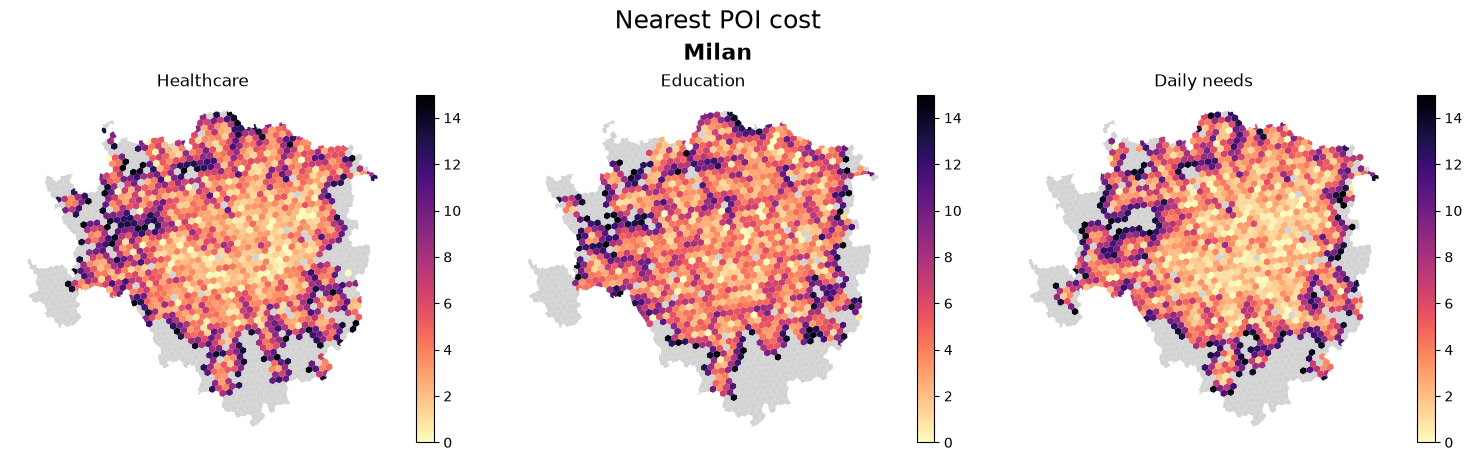

In [ ]:
#Categories and cities to plot
categories = ["healthcare", "education", "daily_needs"]
cities = ["milan"]

n_rows, n_cols = len(cities), len(categories)

fig = plt.figure(figsize=(5 * n_cols, 4.5 * n_rows), layout="constrained")
subfigs = fig.subfigures(n_rows, 1, squeeze=False).flat  # one sub-figure per city

for subfig, city in zip(subfigs, cities):
    subfig.suptitle(city.title(), fontsize=16, fontweight="bold")
    axes = subfig.subplots(1, n_cols, squeeze=False).flat

    for ax, category in zip(axes, categories):
        nearest_poi_costs[city].plot(
            column=f"nearest_cost_{category}_1",
            ax=ax,
            legend=True,
            cmap="magma_r",  # reversed because lower cost is better
            vmin=0,
            vmax=max_cost,
            edgecolor="none",
            missing_kwds={"color": "lightgrey"},
        )
        ax.set_title(category.replace("_", " ").capitalize())
        ax.axis("off")

fig.suptitle("Nearest POI cost", fontsize=18)
plt.show()


## 3. Hansen Accessibility

Hansen accessibility sums reachable opportunities while applying exponential distance decay. Nearby POIs contribute more than POIs close to the travel-time threshold.

In [ ]:
hansen_scores = {}

for city in city_data:
    name = city["name"]
    epsg = city["epsg"]

    hansen_scores[name] = acx.compute_hansen_accessibility(
        graph=graphs[name],
        hexes=hexes[name].to_crs(epsg),
        pois=pois[name].to_crs(epsg),
        max_cost=max_cost,
        cost_attr=cost_attr,
        id_col="hex_id",
        category_col="category",
        default_poi_weight=1.0,
        beta=0.15,
        max_distance_from_graph=max_distance_from_graph,
        show_progress=True,
    )
    acx.save_gdf(hansen_scores[name], results_path / f"hansen_accessibility_{name}.geojson")

# Uncomment to read hansen scores costs counts instead of recomputing
# hansen_scores = {
#     city["name"]: acx.read_gdf(results_path / f"hansen_accessibility_{city['name']}.geojson")
#     for city in city_data
# }

### Visual Hansen

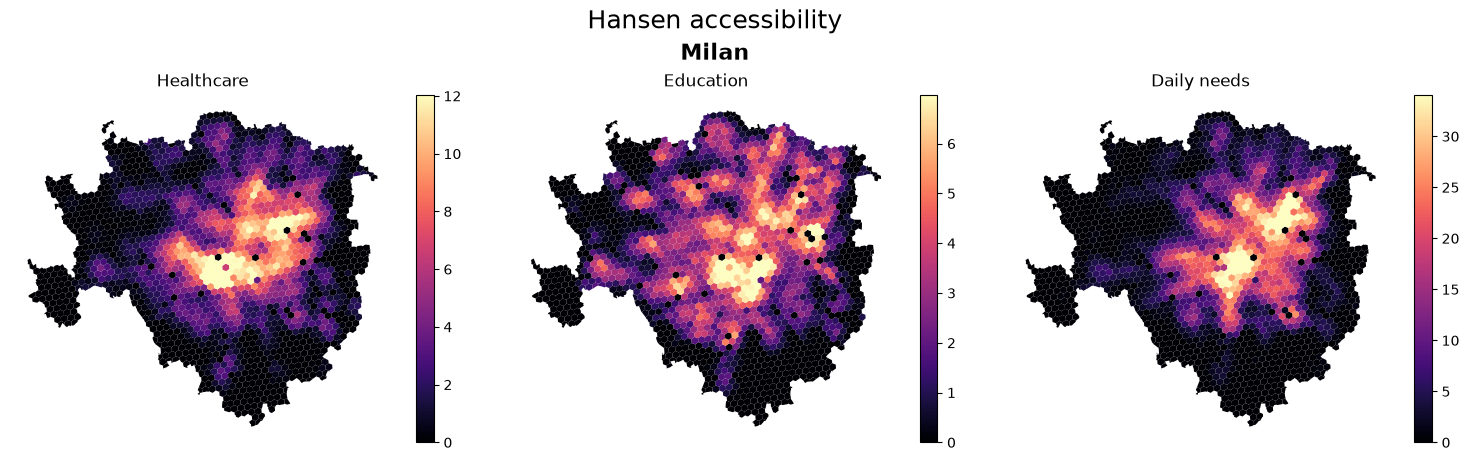

In [ ]:
#Categories and cities to plot
categories = ["healthcare", "education", "daily_needs"]
cities = ["milan"]

n_rows, n_cols = len(cities), len(categories)

# Shared colour scale per category (same across cities, so rows are comparable)
limits = {}
for category in categories:
    metric = f"hansen_{category}"
    limits[category] = (
        min(hansen_scores[city][metric].quantile(0.02) for city in cities),
        max(hansen_scores[city][metric].quantile(0.98) for city in cities),
    )

fig = plt.figure(figsize=(5 * n_cols, 4.5 * n_rows), layout="constrained")
subfigs = fig.subfigures(n_rows, 1, squeeze=False).flat  # one sub-figure per city

for subfig, city in zip(subfigs, cities):
    subfig.suptitle(city.title(), fontsize=16, fontweight="bold")
    axes = subfig.subplots(1, n_cols, squeeze=False).flat

    for ax, category in zip(axes, categories):
        vmin, vmax = limits[category]
        hansen_scores[city].plot(
            column=f"hansen_{category}",
            ax=ax,
            legend=True,
            cmap="magma",
            vmin=vmin,
            vmax=vmax,
            edgecolor="none",
            missing_kwds={"color": "lightgrey"},
        )
        ax.set_title(category.replace("_", " ").capitalize())
        ax.axis("off")

fig.suptitle("Hansen accessibility per category", fontsize=18)
plt.show()


## 4. Two-Step Floating Catchment Area Accessibility

2SFCA combines POI supply with population demand. With no explicit capacity column, each POI contributes the same default supply. The exponential decay option produces an E2SFCA-like measure.

## Prepare Population Demand for 2SFCA

Only 2SFCA requires population demand. The other accessibility measures can be calculated directly from hexagons, POIs, and the walking network.

In [ ]:
worldpop_rasters = {}
hexes_with_population = {}

for city in city_data:
    name = city["name"]
    raster_path = population_path / f"{name}_worldpop_{worldpop_year}.tif"

    worldpop_rasters[name] = acx.get_worldpop_raster(
        aoi=aois[name],
        year=worldpop_year,
        clip=True,
        save_path=raster_path,
    )
    hexes_with_population[name] = acx.map_population_to_hexes(
        hexes[name],
        worldpop_rasters[name],
        metric_crs=city["epsg"],
    )
    acx.save_gdf(
        hexes_with_population[name],
        population_path / f"hexes_population_{name}.geojson",
    )

# Uncomment to read saved population hexes instead of downloading and mapping again.
# hexes_with_population = {
#     city["name"]: acx.read_gdf(population_path / f"hexes_population_{city['name']}.geojson")
#     for city in city_data
# }

In [ ]:
sfca_scores = {}

for city in city_data:
    name = city["name"]
    epsg = city["epsg"]

    sfca_scores[name] = acx.compute_2sfca_accessibility(
        graph=graphs[name],
        hexes=hexes_with_population[name].to_crs(epsg),
        pois=pois[name].to_crs(epsg),
        max_cost=max_cost,
        cost_attr=cost_attr,
        demand_col="population",
        id_col="hex_id",
        category_col="category",
        supply_col=None,
        default_supply=1.0,
        max_distance_from_graph=max_distance_from_graph,
        decay="exp",
        beta=0.15,
        show_progress=True,
    )
    acx.save_gdf(sfca_scores[name], results_path / f"sfca_accessibility_{name}.geojson")

# Uncomment to read saved sfca scores instead of recomputing
# sfca_scores = {
#     city["name"]: acx.read_gdf(results_path / f"sfca_accessibility_{city['name']}.geojson")
#     for city in city_data
# }

### Visual 2SFCA

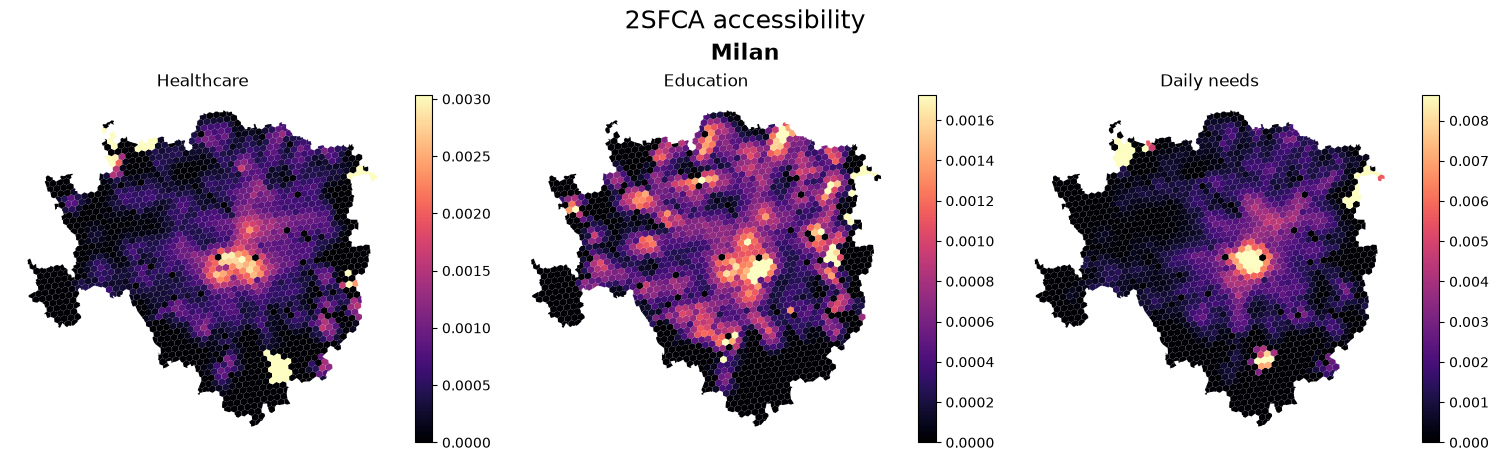

In [ ]:
#Categories and cities to plot
categories = ["healthcare", "education", "daily_needs"]
cities = ["milan"]

n_rows, n_cols = len(cities), len(categories)

# Shared colour scale per category (same across cities, so rows are comparable)
limits = {}
for category in categories:
    metric = f"sfca_{category}"
    limits[category] = (
        min(sfca_scores[city][metric].quantile(0.02) for city in cities),
        max(sfca_scores[city][metric].quantile(0.98) for city in cities),
    )

fig = plt.figure(figsize=(5 * n_cols, 4.5 * n_rows), layout="constrained")
subfigs = fig.subfigures(n_rows, 1, squeeze=False).flat  # one sub-figure per city

for subfig, city in zip(subfigs, cities):
    subfig.suptitle(city.title(), fontsize=16, fontweight="bold")
    axes = subfig.subplots(1, n_cols, squeeze=False).flat

    for ax, category in zip(axes, categories):
        vmin, vmax = limits[category]
        sfca_scores[city].plot(
            column=f"sfca_{category}",
            ax=ax,
            legend=True,
            cmap="magma",
            vmin=vmin,
            vmax=vmax,
            edgecolor="none",
            missing_kwds={"color": "lightgrey"},
        )
        ax.set_title(category.replace("_", " ").capitalize())
        ax.axis("off")

fig.suptitle("2SFCA accessibility", fontsize=18)
plt.show()


## Compare Accessibility Outputs

Each function returns one row per hex. The column prefixes identify the measure:

- `count_`: reachable POI counts
- `nearest_cost_`: nearest POI travel cost
- `hansen_`: Hansen accessibility
- `sfca_`: 2SFCA accessibility

To make the four measures comparable side by side, each is min-max normalized to a 0–1 score, using its 2nd–98th percentile range and clipping values outside it. Nearest cost is inverted, so for every map **1 = best accessibility** and **0 = worst**. Grey hexes have no reachable POI within `max_cost`.

Read these maps for their *spatial patterns*, i.e. where each measure finds high or low access. Do not compare the values across measures: each score is relative to its own range, so a 0.6 in Hansen and a 0.6 in 2SFCA do not mean the same thing.


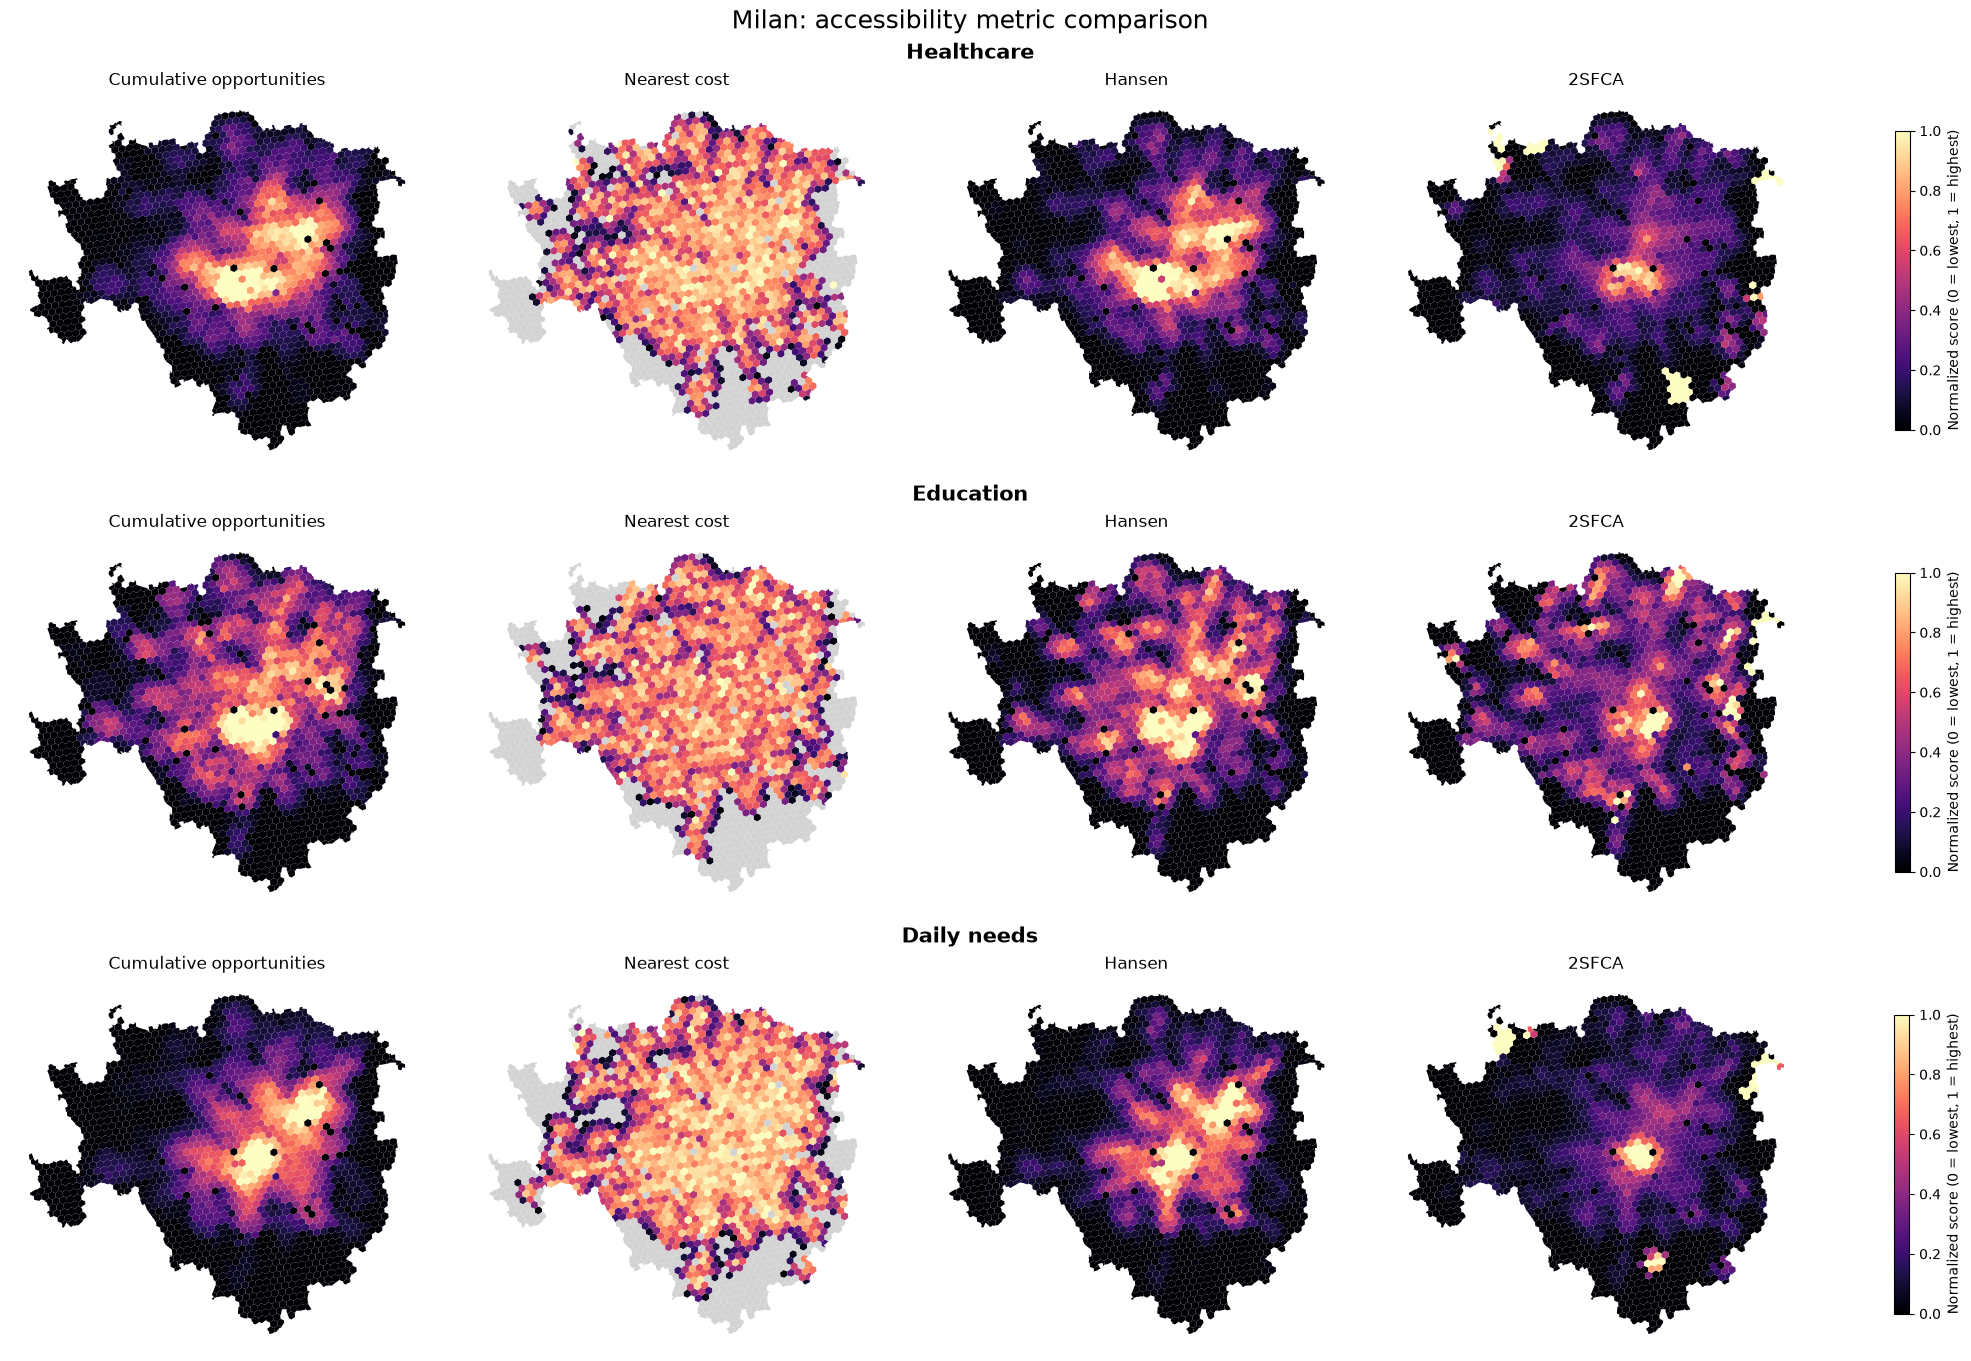

In [17]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

#Categories and cities to plot
categories = ["healthcare", "education", "daily_needs"]
cities = ["milan"]

# (results dict, column template, title) for each metric
metrics = [
    (accessible_counts, "count_{category}",          "Cumulative opportunities"),
    (nearest_poi_costs, "nearest_cost_{category}_1", "Nearest cost"),  # inverted below: lower cost = higher score
    (hansen_scores,     "hansen_{category}",         "Hansen"),
    (sfca_scores,       "sfca_{category}",           "2SFCA"),
]

cmap = "magma"
sm = ScalarMappable(norm=Normalize(vmin=0, vmax=1), cmap=cmap)  # shared legend for all normalized maps

# One figure per city, one row per category, one column per metric
for city in cities:
    fig = plt.figure(figsize=(5 * len(metrics), 4.5 * len(categories)), layout="constrained")
    subfigs = fig.subfigures(len(categories), 1, squeeze=False).flat  # one row per category

    for subfig, category in zip(subfigs, categories):
        subfig.suptitle(category.replace("_", " ").capitalize(), fontsize=15, fontweight="bold")
        axes = list(subfig.subplots(1, len(metrics), squeeze=False).flat)

        for ax, (results, template, title) in zip(axes, metrics):
            column = template.format(category=category)

            # Same bounds as the individual maps above, now used for min-max normalization
            if column.startswith("nearest_cost"):
                vmin, vmax = 0, max_cost
            else:
                vmin = min(results[c][column].quantile(0.02) for c in cities)
                vmax = max(results[c][column].quantile(0.98) for c in cities)

            # Scale to 0-1 (values outside the 2-98% range are clipped)
            span = (vmax - vmin) or 1
            norm = ((results[city][column] - vmin) / span).clip(0, 1)
            if column.startswith("nearest_cost"):
                norm = 1 - norm  # 1 = POI right next door, 0 = at max_cost

            results[city].assign(norm_score=norm).plot(
                column="norm_score",
                ax=ax,
                cmap=cmap,
                vmin=0,
                vmax=1,
                edgecolor="none",
                missing_kwds={"color": "lightgrey"},
            )
            ax.set_title(title)
            ax.axis("off")

        subfig.colorbar(sm, ax=axes, shrink=0.8, label="Normalized score (0 = lowest, 1 = highest)")

    fig.suptitle(f"{city.title()}: accessibility metric comparison", fontsize=18)
    plt.show()


## Saved Outputs

The `results` folder contains separate GeoJSON files for each accessibility measure and city. These outputs can be used directly in later mapping and statistical analysis.